In [1]:
import random
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

# Usage
set_seed(42)

In [119]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
alpha = 0.2

set_seed(42)

value_estimator, states, index_set, _ = load_val_estimate(run_id, alpha, device="mps")
collector = Collector(None, None)
core, states, expr = collector.load_collected(run_dir)


core.S = 7000
print("states shape:", states.shape)
in_dim = value_estimator.in_dim

# Train LCB ################
    

lcb = LCB(
    2, 
    value_estimator,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model = LCBModel(core, lcb)
model.num_train_steps_per_t = 200
model.num_baseline_epochs_per_step = 1
X = model.train()

print("effective N = ", model.num_steps/(7000*20))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
states shape: (20, 70000, 2)
LCB Model has S =  7000
Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
effective N =  16.273878571428572


In [125]:
model_more_train = model
model_more_train.lcb.lam_max = 10
model_more_train.lcb.fix_lambda = False
# model_more_train.lcb.baseline_lr = 5e-5

model_more_train.num_train_steps_per_t = 1
X_more_train = model_more_train.train()

Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...


In [133]:
model_more_train_delta_0p2 = model
model_more_train_delta_0p2.lcb.lam_max = 10
model_more_train_delta_0p2.lcb.fix_lambda = False
model_more_train_delta_0p2.lcb.delta = 0.2

model_more_train_delta_0p2.num_train_steps_per_t = 1
model_more_train_delta_0p2.num_steps = 0
X_more_train_delta_0p2 = model_more_train_delta_0p2.train()
print("effective N (delta=0.2) = ", model_more_train_delta_0p2.num_steps/(7000*20))


Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
effective N (delta=0.2) =  5.000392857142857


In [138]:
model_more_train_delta_0p3 = model
model_more_train_delta_0p3.lcb.lam_max = 10
model_more_train_delta_0p3.lcb.fix_lambda = False
model_more_train_delta_0p3.lcb.delta = 0.3

model_more_train_delta_0p3.num_train_steps_per_t = 1
model_more_train_delta_0p3.num_steps = 0
X_more_train_delta_0p3 = model_more_train_delta_0p3.train()
print("effective N (delta=0.3) = ", model_more_train_delta_0p2.num_steps/(7000*20))


Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
effective N (delta=0.3) =  3.94095


In [ ]:
model_more_train_delta_0p3 = model
model_more_train_delta_0p3.lcb.lam_max = 10
model_more_train_delta_0p3.lcb.fix_lambda = False
model_more_train_delta_0p3.lcb.delta = 0.3

model_more_train_delta_0p3.num_train_steps_per_t = 1
model_more_train_delta_0p3.num_steps = 0
X_more_train_delta_0p3 = model_more_train_delta_0p3.train()
print("effective N (delta=0.3) = ", model_more_train_delta_0p2.num_steps/(7000*20))


In [ ]:
model_more_train_delta_0p05 = model
model_more_train_delta_0p05.lcb.lam_max = 10
model_more_train_delta_0p05.lcb.fix_lambda = False
model_more_train_delta_0p05.lcb.delta = 0.05

model_more_train_delta_0p05.num_train_steps_per_t = 1
model_more_train_delta_0p05.num_steps = 0
X_more_train_delta_0p05 = model_more_train_delta_0p05.train()
print("effective N (delta=0.05) = ", model_more_train_delta_0p05.num_steps/(7000*20))

Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
effective N (delta=0.05) =  8.250085714285714


In [228]:
model_more_train_delta_0p005 = model
model_more_train_delta_0p005.lcb.lam_max = 20
model_more_train_delta_0p005.lcb.fix_lambda = False
model_more_train_delta_0p005.lcb.delta = 0.005

model_more_train_delta_0p005.num_train_steps_per_t = 1
model_more_train_delta_0p005.num_steps = 0
X_more_train_delta_0p005 = model_more_train_delta_0p005.train()
print("effective N (delta=0.005) = ", model_more_train_delta_0p005.num_steps/(7000*20))

Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
effective N (delta=0.005) =  10.199435714285714


In [ ]:
model_more_train_delta_0p0001_asym = model
model_more_train_delta_0p0001_asym.lcb.lam_max = 20
model_more_train_delta_0p0001_asym.lcb.fix_lambda = False
model_more_train_delta_0p0001_asym.lcb.symmetric = False
model_more_train_delta_0p0001_asym.lcb.delta = 1e-3
model_more_train_delta_0p005.lcb.train_baseline = True
model_more_train_delta_0p0001_asym.num_train_steps_per_t = 100
model_more_train_delta_0p0001_asym.num_steps = 0
X_more_train_delta_0p0001_asym = model_more_train_delta_0p0001_asym.train()
print("effective N (delta=1e-3, asymmetric) = ", model_more_train_delta_0p0001_asym.num_steps/(7000*20))

Training LCB at t=18...
Training LCB at t=17...


KeyboardInterrupt: 

In [237]:
X_more_train_delta_0p0001_asym.shape

(7000, 2)

In [126]:
X_more_steps_infer = model_more_train.infer()
print(model_more_train.lcb.lambdas)

[1.6707002955150956, 1.7184455864195223, 1.775904379137486, 1.8521952128303565, 1.8298801998235532, 1.8531578826235995, 1.8653916866757896, 2.089591290418171, 2.4115745226969674, 2.722146169086831, 2.709912365034641, 2.912759625563462, 3.0220416438699154, 2.7058344303505777, 3.4997218084252735, 2.7155479321641143, 2.6825567475505316, 4.203894623450574, None, None]


In [127]:
model_more_train.num_steps/(7000*20)

6.7686714285714285

In [ ]:
X_infer = model.infer()
model.num_steps/(7000*200)

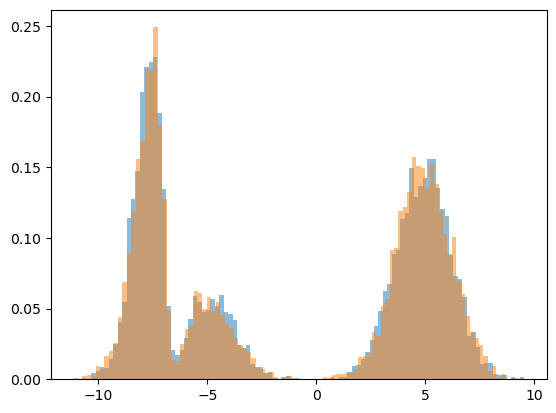

In [231]:
import matplotlib.pyplot as plt
# plt.scatter([ :, 0], X[ :, 1], c='blue', alpha=0.5)
plt.hist(X_rs[0, :, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_more_steps_infer[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_more_train_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_more_train_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_more_train_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_more_train_delta_0p3[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [ ]:
from animate_2d import animate_val_predictions
alpha_str = str(alpha).replace(".", "p")
animate_val_predictions(states, index_set, lcb, outfile=f"{run_dir}/lcb_{alpha_str}_SYM.gif")


Predictions shape: (20, 2500)
Value prediction range: -13.815511 0.41842315


'toy_data_runs/20260122_202321_157606/lcb_0p2_SYM.gif'

In [103]:
import numpy as np

class RejectionSampling:
    """
    Simple rejection sampling policy analogous to LCBModel.lcb_step, but with
    acceptance probability:   p_accept = exp(v_t(x_t) - B)

    where v_t is provided in *log-space* by value_estimator.predict_under_log(...),
    and B is a user-chosen constant (typically >= max log v so p<=1 mostly).
    """
    def __init__(self, core, value_estimator, B: float, N: int = 5):
        self.core = core
        self.core.reset()
        self.value_estimator = value_estimator
        self.index_set = self.core.model_config["index_set"]
        self.B = float(B)
        self.N = int(N)

        self.S = self.core.S
        self.num_steps = 0  # total proposals used (like LCBModel.num_steps)

    def rs_step(self):
        """
        Perform one reverse-time step (t+1 -> t) using rejection sampling.
        Mirrors LCBModel.lcb_step structure.

        Returns:
            accepted_states: (S, d) np.ndarray
            num_proposals:   length-S list[int] proposals consumed per chain
        """
        tp1 = self.core.t  # current time index is "t+1" in their convention
        if tp1 < 0:
            raise ValueError(f"rs_step called with core.t={tp1}; expected t>=1 (so we can go to t-1).")

        Xtp1 = self.core.X  # (S, d)
        S = Xtp1.shape[0]

        # proposals per active chain per loop-iteration
        self.core.N = self.N

        active = list(range(S))
        accepted_states = [None] * S
        num_proposals = [0] * S

        # Loop until every chain accepts a proposal
        while active:
            # Propose candidates for currently-active indices.
            # Expected shape: (N, len(active), d)
            Xt = self.core.propose_external(Xtp1[active], tp1, N=self.core.N)

            # log v_t for each proposed state at time t = tp1-1
            # expected shape: (N, len(active))
            logvt = self.value_estimator.predict_under_log(Xt, self.index_set[tp1 - 1])

            acc = np.exp(logvt - self.B)
            acc = np.clip(acc, 0.0, 1.0)

            u = np.random.rand(*acc.shape)

            # Ensure acc is shaped (A, N): rows = active chains, cols = proposals
            # A = len(active), N = self.core.N
            A = len(active)
            N = self.core.N
            if acc.shape == (N, A):
                acc = acc.T
                u = u.T
            elif acc.shape != (A, N):
                raise ValueError(f"Unexpected acc shape {acc.shape}; expected {(A, N)} or {(N, A)}")

            new_active = []
            for j, orig_idx in enumerate(active):
                ok = np.where(acc[j, :] > u[j, :])[0]
                if ok.size:
                    first = int(ok[0])
                    # Xt could be (N, A, d) or (A, N, d) depending on Core; handle both.
                    if Xt.shape[:2] == (N, A):
                        accepted_states[orig_idx] = Xt[first, j]
                    elif Xt.shape[:2] == (A, N):
                        accepted_states[orig_idx] = Xt[j, first]
                    else:
                        raise ValueError(f"Unexpected Xt shape {Xt.shape}; expected {(N, A, 'd')} or {(A, N, 'd')}")
                    num_proposals[orig_idx] += first + 1
                else:
                    new_active.append(orig_idx)
                    num_proposals[orig_idx] += N

            active = new_active


        accepted_states = np.stack(accepted_states, axis=0)
        self.core.commit(accepted_states)
        self.num_steps += int(sum(num_proposals))
        return accepted_states, num_proposals

    def set_S(self, S: int):
        self.core.S = int(S)
        self.S = int(S)
        self.core.reset()

    def calc_samples(self):
        """
        Roll out samples using rejection sampling, returning an array of shape (T+1, S, d),
        matching LCBModel.calc_samples().
        """
        self.core.reset()
        self.num_steps = 0

        # initial noisy state at time T
        init_props = self.core.propose()
        if init_props.ndim == 3:
            x_init = init_props[:, 0, :]
        else:
            x_init = init_props
        self.core.commit(x_init)

        T_plus_1 = self.core.T + 1
        d = x_init.shape[-1]
        states = np.empty((T_plus_1, self.S, d))
        states[self.core.t + 1] = x_init  # time index T

        while self.core.t >= 0:
            states_t, _ = self.rs_step()
            states[self.core.t] = states_t

        return states


# ---------------------------------------------------------------------
# Example usage (mirrors how you use LCBModel)
# ---------------------------------------------------------------------
# rs = RejectionSampling(core=core, value_estimator=value_estimator, B=YOUR_B, N=5)
# rs.core.S = 5000
# rs.set_S(5000)
# states = rs.calc_samples()
# print("num proposals:", rs.num_steps)


rs = RejectionSampling(core=core, value_estimator=value_estimator, B=1/alpha)
rs.core.S = 7000
rs.set_S(7000)
X_rs = rs.calc_samples()
print("proposal per timestep ratio:", rs.num_steps/(7000*20))


proposal per timestep ratio: 64.16353571428571


In [102]:
X_rs.shape

(20, 700, 2)

In [76]:
X_lcb_bo2_candidates = X.reshape(20, 5000, 2, 2)[0]
X_lcb_bo2_candidates.shape


(5000, 2, 2)

In [151]:
X_more_train_delta_0p05.shape

(7000, 2)

In [215]:
X_lcb_boN

array([[-4.78777688,  3.74304161],
       [ 5.32386949,  3.42547786],
       [ 4.22387211,  3.10356573],
       [ 6.29407242,  6.43496815],
       [ 3.95734953, -3.79036147],
       [-4.18149382, -8.13328378],
       [-0.13705832, -0.59791738]])

In [222]:
X_lcb_boN_candidates[0, 0, :]

array([-4.78777688e+00,  8.35529549e-01, -7.50381569e+00, -7.47804543e-01,
        5.66876293e+00,  1.35810384e+00,  4.86044267e+00, -3.51765271e-01,
       -8.08183919e+00,  1.58978720e+00, -7.91779803e+00, -2.74455840e-01,
        7.56289170e+00,  9.27318315e-01, -7.75218022e+00,  1.48757889e+00,
       -4.38850000e+00,  7.68280871e-01,  4.15974156e+00, -1.32388061e+00,
        5.70340358e+00, -3.98425660e-01,  2.42377840e+00,  6.21277068e-01,
       -8.23874525e+00,  1.06611888e+00,  2.18170433e+00,  5.24616010e-01,
        4.58084371e+00,  3.04383954e-01, -7.33305190e+00,  2.22297374e+00,
        3.49171143e+00,  5.10183631e-01, -7.10636915e+00,  8.87928620e-01,
        4.82088389e+00, -1.80926886e-01,  4.88734362e+00,  1.03948899e-01,
        5.73779778e+00,  8.85608909e-01, -7.56059723e+00, -7.48846828e-01,
        5.39998792e+00, -1.62750377e-01,  3.44356565e+00,  2.32016482e+00,
       -7.03277175e+00,  1.62031202e+00,  6.16891341e+00,  1.00059561e+00,
       -7.42624976e+00,  

[2, 6, 10, 14, 4, 6, 0]


(array([12.73622842,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        , 12.73622842,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        , 12.73622842,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0. 

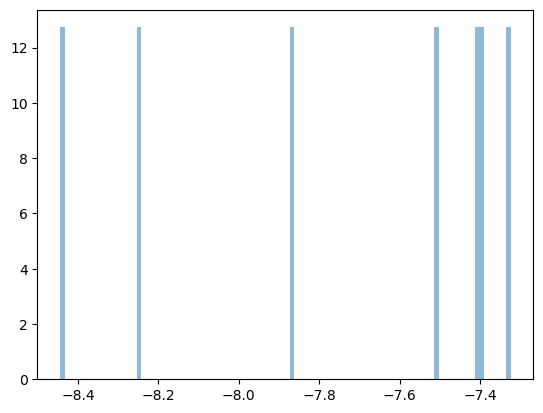

In [227]:
S = 7
X_lcb_boN_candidates = X_more_train_delta_0p05.reshape(S, 2, -1)
rewards = np.where(X_lcb_bo2_candidates[:, 0, :] < -7, 1, 0)

best_idxs = []
for j in range(rewards.shape[0]):
    best_idxs.append(np.argmax(rewards[j, :]))
print(best_idxs)
# X_lcb_bo2 = np.stack(X_lcb_bo2_list, axis=0)
X_lcb_boN = np.array([X_lcb_boN_candidates[k, :, best_idxs[k]] for k in range(S)])

plt.hist(X_lcb_boN[:, 0], bins=100, density=True, alpha=0.5)

In [58]:
states.shape

(20, 70000, 2)

(array([0.00300676, 0.00300676, 0.00601352, 0.00526183, 0.01202705,
        0.01728888, 0.02856423, 0.04434973, 0.0706589 , 0.09621637,
        0.14507625, 0.16687527, 0.22776219, 0.24730614, 0.26384333,
        0.23076895, 0.18491584, 0.11275356, 0.04735649, 0.01503381,
        0.01804057, 0.02706085, 0.04434973, 0.04810819, 0.06163861,
        0.05337002, 0.05261833, 0.05938354, 0.06013523, 0.05412171,
        0.05562509, 0.0466048 , 0.04059128, 0.03232269, 0.031571  ,
        0.02555747, 0.02104733, 0.01127536, 0.00826859, 0.01052367,
        0.00676521, 0.00451014, 0.00225507, 0.00225507, 0.00075169,
        0.00150338, 0.        , 0.        , 0.00150338, 0.        ,
        0.00150338, 0.        , 0.        , 0.00075169, 0.        ,
        0.        , 0.00075169, 0.00150338, 0.        , 0.00225507,
        0.00150338, 0.00526183, 0.00977198, 0.00451014, 0.02104733,
        0.01428212, 0.01954395, 0.02706085, 0.04059128, 0.04510142,
        0.06464537, 0.07441735, 0.08268594, 0.09

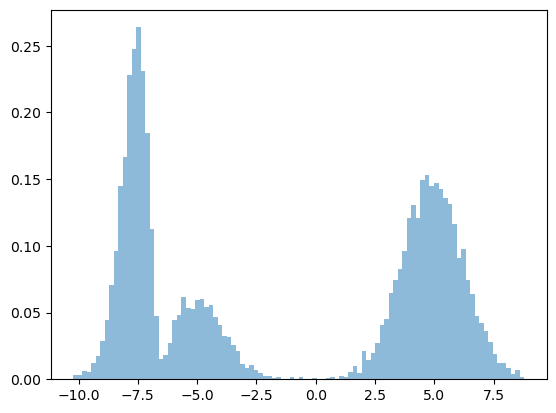

In [60]:
import matplotlib.pyplot as plt
# plt.hist(states[1, :, 0], bins=100, density=True, alpha=0.5, label="RS t=0")
plt.hist(X[:, 0], bins=100, density=True, alpha=0.5, label="RS t=0")
# plt.hist(X_lcb_bo2[:, 0], bins=50, density=True, alpha=0.5, label="RS t=0")

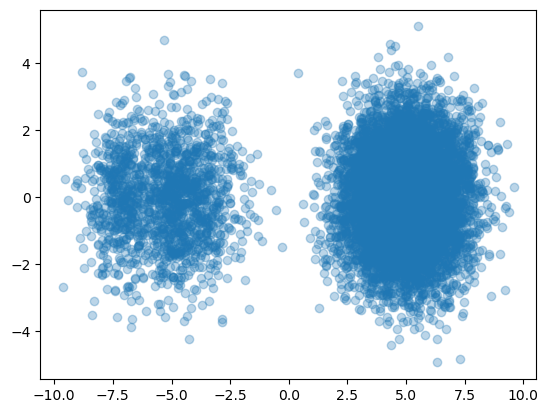

In [12]:
plt.scatter(X[0, :, 0], X[0, :, 1], alpha=0.3)

In [10]:
X.shape

(20, 5000, 2)